# **Bioinformatics Project - Computational Drug Discovery [Part 2] Exploratory Data Analysis**

Chanin Nantasenamat

[*'Data Professor' YouTube channel*](http://youtube.com/dataprofessor)

In this Jupyter notebook, we will be building a real-life **data science project** that you can include in your **data science portfolio**. Particularly, we will be building a machine learning model using the ChEMBL bioactivity data.

In **Part 2**, we will be performing Descriptor Calculation and Exploratory Data Analysis.

---

## **Install conda and rdkit**

In [20]:
%pip install rdkit

In [3]:
import sys
print(sys.version)
!{sys.executable} -m pip install rdkit
!{sys.executable} -m pip show rdkit

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 60.8 MB/s  0:00:00
Name: rdkit
Version: 2026.9.1
Summary: A collection of chemoinformatics and machine-learning software written in C++ and Python
Home-page: https://github.com/kuelumbus/rdkit-pypi
Author: Christopher Kuenneth
Author-email: chris@kuenneth.dev
License: BSD-3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: numpy, Pillow
Required-by: 


In [4]:
import rdkit
print(rdkit.__version__)

2026.09.1


## **Load bioactivity data**

In [5]:
import pandas as pd

In [6]:
df = pd.read_csv('schistosoma mansoni_03_bioactivity_data_curated.csv')

## **Calculate Lipinski descriptors**
Christopher Lipinski, a scientist at Pfizer, came up with a set of rule-of-thumb for evaluating the **druglikeness** of compounds. Such druglikeness is based on the Absorption, Distribution, Metabolism and Excretion (ADME) that is also known as the pharmacokinetic profile. Lipinski analyzed all orally active FDA-approved drugs in the formulation of what is to be known as the **Rule-of-Five** or **Lipinski's Rule**.

The Lipinski's Rule stated the following:
* Molecular weight < 500 Dalton
* Octanol-water partition coefficient (LogP) < 5
* Hydrogen bond donors < 5
* Hydrogen bond acceptors < 10

### **Import libraries**

In [7]:
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski

### **Calculate descriptors**

In [8]:
# Inspired by: https://codeocean.com/explore/capsules?query=tag:data-curation

def lipinski(smiles, verbose=False):

    moldata= []
    for elem in smiles:
        mol=Chem.MolFromSmiles(elem)
        moldata.append(mol)

    baseData= np.arange(1,1)
    i=0
    for mol in moldata:

        desc_MolWt = Descriptors.MolWt(mol)
        desc_MolLogP = Descriptors.MolLogP(mol)
        desc_NumHDonors = Lipinski.NumHDonors(mol)
        desc_NumHAcceptors = Lipinski.NumHAcceptors(mol)

        row = np.array([desc_MolWt,
                        desc_MolLogP,
                        desc_NumHDonors,
                        desc_NumHAcceptors])

        if(i==0):
            baseData=row
        else:
            baseData=np.vstack([baseData, row])
        i=i+1

    columnNames=["MW","LogP","NumHDonors","NumHAcceptors"]
    descriptors = pd.DataFrame(data=baseData,columns=columnNames)

    return descriptors

In [9]:
df_lipinski = lipinski(df.canonical_smiles)

### **Combine DataFrames**

Let's take a look at the 2 DataFrames that will be combined.

In [10]:
df_lipinski

,MW,LogP,NumHDonors,NumHAcceptors
0,302.231,0.06826,0.0,9.0
1,302.231,0.06826,0.0,9.0
2,314.192,0.14586,0.0,8.0
3,296.202,0.00676,0.0,8.0
4,296.202,0.00676,0.0,8.0
5,221.197,0.47218,0.0,6.0
6,193.187,0.90818,0.0,5.0
7,177.119,0.43968,0.0,5.0
8,203.157,0.55228,1.0,5.0
9,263.256,2.51368,0.0,4.0


In [11]:
df

,molecule_chembl_id,canonical_smiles,standard_value,class
0,CHEMBL576624,N#Cc1c(-c2csc(-c3no[n+]([O-])c3C#N)c2)no[n+]1[O-],350.0,active
1,CHEMBL569420,N#Cc1c(-c2ccc(-c3no[n+]([O-])c3C#N)s2)no[n+]1[O-],400.0,active
2,CHEMBL570121,N#Cc1c(-c2cc(F)cc(-c3no[n+]([O-])c3C#N)c2)no[n...,480.0,active
3,CHEMBL582970,N#Cc1c(-c2ccc(-c3no[n+]([O-])c3C#N)cc2)no[n+]1...,1000.0,active
4,CHEMBL575013,N#Cc1c(-c2cccc(-c3no[n+]([O-])c3C#N)c2)no[n+]1...,3500.0,intermediate
5,CHEMBL576265,N#Cc1c(C(=O)c2cccs2)no[n+]1[O-],63.0,active
6,CHEMBL583780,N#Cc1c(-c2cccs2)no[n+]1[O-],3500.0,intermediate
7,CHEMBL565242,N#Cc1c(-c2ccco2)no[n+]1[O-],2800.0,intermediate
8,CHEMBL570132,N#Cc1c(-c2ccc(O)cc2)no[n+]1[O-],17900.0,inactive
9,CHEMBL576082,N#Cc1c(-c2ccc(-c3ccccc3)cc2)no[n+]1[O-],15800.0,inactive


Now, let's combine the 2 DataFrame

In [12]:
df_combined = pd.concat([df,df_lipinski], axis=1)

In [13]:
df_combined

,molecule_chembl_id,canonical_smiles,standard_value,class,MW,LogP,NumHDonors,NumHAcceptors
0,CHEMBL576624,N#Cc1c(-c2csc(-c3no[n+]([O-])c3C#N)c2)no[n+]1[O-],350.0,active,302.231,0.06826,0.0,9.0
1,CHEMBL569420,N#Cc1c(-c2ccc(-c3no[n+]([O-])c3C#N)s2)no[n+]1[O-],400.0,active,302.231,0.06826,0.0,9.0
2,CHEMBL570121,N#Cc1c(-c2cc(F)cc(-c3no[n+]([O-])c3C#N)c2)no[n...,480.0,active,314.192,0.14586,0.0,8.0
3,CHEMBL582970,N#Cc1c(-c2ccc(-c3no[n+]([O-])c3C#N)cc2)no[n+]1...,1000.0,active,296.202,0.00676,0.0,8.0
4,CHEMBL575013,N#Cc1c(-c2cccc(-c3no[n+]([O-])c3C#N)c2)no[n+]1...,3500.0,intermediate,296.202,0.00676,0.0,8.0
5,CHEMBL576265,N#Cc1c(C(=O)c2cccs2)no[n+]1[O-],63.0,active,221.197,0.47218,0.0,6.0
6,CHEMBL583780,N#Cc1c(-c2cccs2)no[n+]1[O-],3500.0,intermediate,193.187,0.90818,0.0,5.0
7,CHEMBL565242,N#Cc1c(-c2ccco2)no[n+]1[O-],2800.0,intermediate,177.119,0.43968,0.0,5.0
8,CHEMBL570132,N#Cc1c(-c2ccc(O)cc2)no[n+]1[O-],17900.0,inactive,203.157,0.55228,1.0,5.0
9,CHEMBL576082,N#Cc1c(-c2ccc(-c3ccccc3)cc2)no[n+]1[O-],15800.0,inactive,263.256,2.51368,0.0,4.0


### **Convert IC50 to pIC50**
To allow **IC50** data to be more uniformly distributed, we will convert **IC50** to the negative logarithmic scale which is essentially **-log10(IC50)**.

This custom function pIC50() will accept a DataFrame as input and will:
* Take the IC50 values from the ``standard_value`` column and converts it from nM to M by multiplying the value by 10$^{-9}$
* Take the molar value and apply -log10
* Delete the ``standard_value`` column and create a new ``pIC50`` column

In [33]:
# https://github.com/chaninlab/estrogen-receptor-alpha-qsar/blob/master/02_ER_alpha_RO5.ipynb

import numpy as np

def pIC50(input_df):
    pIC50_list = []

    for i in input_df['standard_value_norm']:
        molar = i * (10**-9) # Converts nM to M
        pIC50_list.append(-np.log10(molar))

    input_df['pIC50'] = pIC50_list
    x = input_df.drop('standard_value_norm', axis=1)

    return x

Point to note: Values greater than 100,000,000 will be fixed at 100,000,000 otherwise the negative logarithmic value will become negative.

In [24]:
df_combined.standard_value.describe()

,standard_value
count,57.000000
mean,10937.368421
std,16982.855232
min,10.000000
25%,350.000000
50%,3500.000000
75%,10000.000000
max,57500.000000


In [25]:
-np.log10( (10**-9)* 100000000 )

np.float64(1.0)

In [26]:
-np.log10( (10**-9)* 10000000000 )

np.float64(-1.0)

In [27]:
def norm_value(input):
    norm = []

    for i in input['standard_value']:
        if i > 100000000:
          i = 100000000
        norm.append(i)

    input['standard_value_norm'] = norm
    x = input.drop('standard_value', 1)

    return x

We will first apply the norm_value() function so that the values in the standard_value column is normalized.

In [28]:
# Vamos redefinir a função corrigindo o método .drop() usando axis=1 de forma explícita
def norm_value_fixed(input_df):
    norm = []
    for i in input_df['standard_value']:
        if i > 100000000:
          i = 100000000
        norm.append(i)

    input_df['standard_value_norm'] = norm
    x = input_df.drop('standard_value', axis=1)
    return x

df_norm = norm_value_fixed(df_combined)
df_norm

,molecule_chembl_id,canonical_smiles,class,MW,LogP,NumHDonors,NumHAcceptors,standard_value_norm
0,CHEMBL576624,N#Cc1c(-c2csc(-c3no[n+]([O-])c3C#N)c2)no[n+]1[O-],active,302.231,0.06826,0.0,9.0,350.0
1,CHEMBL569420,N#Cc1c(-c2ccc(-c3no[n+]([O-])c3C#N)s2)no[n+]1[O-],active,302.231,0.06826,0.0,9.0,400.0
2,CHEMBL570121,N#Cc1c(-c2cc(F)cc(-c3no[n+]([O-])c3C#N)c2)no[n...,active,314.192,0.14586,0.0,8.0,480.0
3,CHEMBL582970,N#Cc1c(-c2ccc(-c3no[n+]([O-])c3C#N)cc2)no[n+]1...,active,296.202,0.00676,0.0,8.0,1000.0
4,CHEMBL575013,N#Cc1c(-c2cccc(-c3no[n+]([O-])c3C#N)c2)no[n+]1...,intermediate,296.202,0.00676,0.0,8.0,3500.0
5,CHEMBL576265,N#Cc1c(C(=O)c2cccs2)no[n+]1[O-],active,221.197,0.47218,0.0,6.0,63.0
6,CHEMBL583780,N#Cc1c(-c2cccs2)no[n+]1[O-],intermediate,193.187,0.90818,0.0,5.0,3500.0
7,CHEMBL565242,N#Cc1c(-c2ccco2)no[n+]1[O-],intermediate,177.119,0.43968,0.0,5.0,2800.0
8,CHEMBL570132,N#Cc1c(-c2ccc(O)cc2)no[n+]1[O-],inactive,203.157,0.55228,1.0,5.0,17900.0
9,CHEMBL576082,N#Cc1c(-c2ccc(-c3ccccc3)cc2)no[n+]1[O-],inactive,263.256,2.51368,0.0,4.0,15800.0


In [29]:
df_norm.standard_value_norm.describe()

,standard_value_norm
count,57.000000
mean,10937.368421
std,16982.855232
min,10.000000
25%,350.000000
50%,3500.000000
75%,10000.000000
max,57500.000000


In [30]:
df_final = pIC50(df_norm)
df_final

,molecule_chembl_id,canonical_smiles,class,MW,LogP,NumHDonors,NumHAcceptors,pIC50
0,CHEMBL576624,N#Cc1c(-c2csc(-c3no[n+]([O-])c3C#N)c2)no[n+]1[O-],active,302.231,0.06826,0.0,9.0,6.455932
1,CHEMBL569420,N#Cc1c(-c2ccc(-c3no[n+]([O-])c3C#N)s2)no[n+]1[O-],active,302.231,0.06826,0.0,9.0,6.397940
2,CHEMBL570121,N#Cc1c(-c2cc(F)cc(-c3no[n+]([O-])c3C#N)c2)no[n...,active,314.192,0.14586,0.0,8.0,6.318759
3,CHEMBL582970,N#Cc1c(-c2ccc(-c3no[n+]([O-])c3C#N)cc2)no[n+]1...,active,296.202,0.00676,0.0,8.0,6.000000
4,CHEMBL575013,N#Cc1c(-c2cccc(-c3no[n+]([O-])c3C#N)c2)no[n+]1...,intermediate,296.202,0.00676,0.0,8.0,5.455932
5,CHEMBL576265,N#Cc1c(C(=O)c2cccs2)no[n+]1[O-],active,221.197,0.47218,0.0,6.0,7.200659
6,CHEMBL583780,N#Cc1c(-c2cccs2)no[n+]1[O-],intermediate,193.187,0.90818,0.0,5.0,5.455932
7,CHEMBL565242,N#Cc1c(-c2ccco2)no[n+]1[O-],intermediate,177.119,0.43968,0.0,5.0,5.552842
8,CHEMBL570132,N#Cc1c(-c2ccc(O)cc2)no[n+]1[O-],inactive,203.157,0.55228,1.0,5.0,4.747147
9,CHEMBL576082,N#Cc1c(-c2ccc(-c3ccccc3)cc2)no[n+]1[O-],inactive,263.256,2.51368,0.0,4.0,4.801343


In [31]:
df_final.pIC50.describe()

,pIC50
count,57.000000
mean,5.627696
std,0.951133
min,4.240332
25%,5.000000
50%,5.455932
75%,6.455932
max,8.000000


### **Removing the 'intermediate' bioactivity class**
Here, we will be removing the ``intermediate`` class from our data set.

In [51]:
# Criando explicitamente a coluna bioactivity_class para manter a consistência
df_final['bioactivity_class'] = df_final['class']
df_2class = df_final[df_final['bioactivity_class'] != 'intermediate']
df_2class

,molecule_chembl_id,canonical_smiles,class,MW,LogP,NumHDonors,NumHAcceptors,pIC50,bioactivity_class
0,CHEMBL576624,N#Cc1c(-c2csc(-c3no[n+]([O-])c3C#N)c2)no[n+]1[O-],active,302.231,0.06826,0.0,9.0,6.455932,active
1,CHEMBL569420,N#Cc1c(-c2ccc(-c3no[n+]([O-])c3C#N)s2)no[n+]1[O-],active,302.231,0.06826,0.0,9.0,6.397940,active
2,CHEMBL570121,N#Cc1c(-c2cc(F)cc(-c3no[n+]([O-])c3C#N)c2)no[n...,active,314.192,0.14586,0.0,8.0,6.318759,active
3,CHEMBL582970,N#Cc1c(-c2ccc(-c3no[n+]([O-])c3C#N)cc2)no[n+]1...,active,296.202,0.00676,0.0,8.0,6.000000,active
5,CHEMBL576265,N#Cc1c(C(=O)c2cccs2)no[n+]1[O-],active,221.197,0.47218,0.0,6.0,7.200659,active
8,CHEMBL570132,N#Cc1c(-c2ccc(O)cc2)no[n+]1[O-],inactive,203.157,0.55228,1.0,5.0,4.747147,inactive
9,CHEMBL576082,N#Cc1c(-c2ccc(-c3ccccc3)cc2)no[n+]1[O-],inactive,263.256,2.51368,0.0,4.0,4.801343,inactive
10,CHEMBL574801,Cc1ccc(-c2no[n+]([O-])c2C#N)cc1,inactive,201.185,1.15510,0.0,4.0,4.950782,inactive
11,CHEMBL578810,COc1ccc(-c2no[n+]([O-])c2C#N)cc1,inactive,217.184,0.85528,0.0,5.0,5.000000,inactive
25,CHEMBL570345,O=C(c1cccs1)c1no[n+]([O-])c1C(=O)c1cccs1,active,306.324,1.89300,0.0,7.0,7.397940,active


---

## **Exploratory Data Analysis (Chemical Space Analysis) via Lipinski descriptors**

### **Import library**

In [37]:
import seaborn as sns
sns.set(style='ticks')
import matplotlib.pyplot as plt

### **Frequency plot of the 2 bioactivity classes**

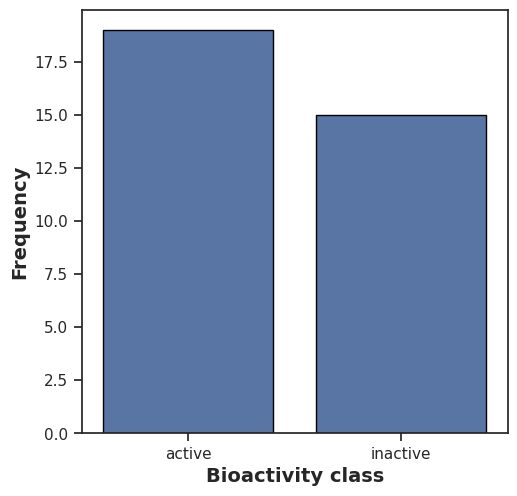

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5.5, 5.5))

sns.countplot(x='bioactivity_class', data=df_2class, edgecolor='black')

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('Frequency', fontsize=14, fontweight='bold')

plt.savefig('plot_bioactivity_class.pdf')

### **Scatter plot of MW versus LogP**

It can be seen that the 2 bioactivity classes are spanning similar chemical spaces as evident by the scatter plot of MW vs LogP.

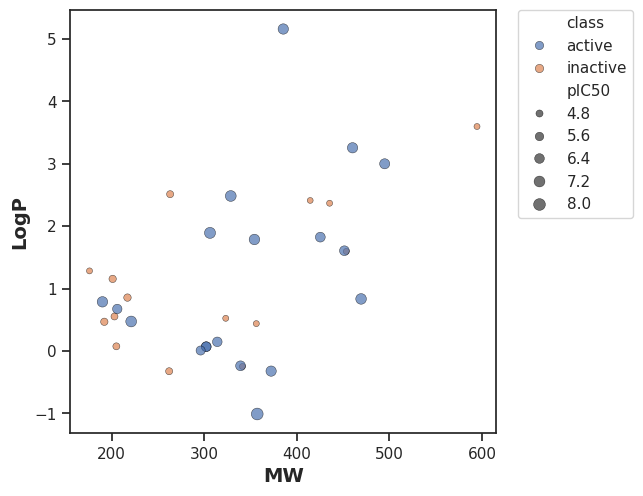

In [53]:
plt.figure(figsize=(5.5, 5.5))

sns.scatterplot(x='MW', y='LogP', data=df_2class, hue='class', size='pIC50', edgecolor='black', alpha=0.7)

plt.xlabel('MW', fontsize=14, fontweight='bold')
plt.ylabel('LogP', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0)
plt.savefig('plot_MW_vs_LogP.pdf')

### **Box plots**

#### **pIC50 value**

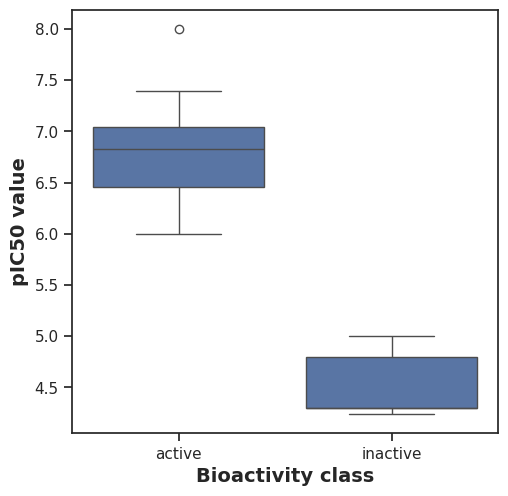

In [40]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'bioactivity_class', y = 'pIC50', data = df_2class)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('pIC50 value', fontsize=14, fontweight='bold')

plt.savefig('plot_ic50.pdf')

**Statistical analysis | Mann-Whitney U Test**

In [41]:
def mannwhitney(descriptor, verbose=False):
  # https://machinelearningmastery.com/nonparametric-statistical-significance-tests-in-python/
  from numpy.random import seed
  from numpy.random import randn
  from scipy.stats import mannwhitneyu

# seed the random number generator
  seed(1)

# actives and inactives
  selection = [descriptor, 'bioactivity_class']
  df = df_2class[selection]
  active = df[df.bioactivity_class == 'active']
  active = active[descriptor]

  selection = [descriptor, 'bioactivity_class']
  df = df_2class[selection]
  inactive = df[df.bioactivity_class == 'inactive']
  inactive = inactive[descriptor]

# compare samples
  stat, p = mannwhitneyu(active, inactive)
  #print('Statistics=%.3f, p=%.3f' % (stat, p))

# interpret
  alpha = 0.05
  if p > alpha:
    interpretation = 'Same distribution (fail to reject H0)'
  else:
    interpretation = 'Different distribution (reject H0)'

  results = pd.DataFrame({'Descriptor':descriptor,
                          'Statistics':stat,
                          'p':p,
                          'alpha':alpha,
                          'Interpretation':interpretation}, index=[0])
  filename = 'mannwhitneyu_' + descriptor + '.csv'
  results.to_csv(filename)

  return results

In [42]:
mannwhitney('pIC50')

,Descriptor,Statistics,p,alpha,Interpretation
0,pIC50,285.0,7.515922e-07,0.05,Different distribution (reject H0)


#### **MW**

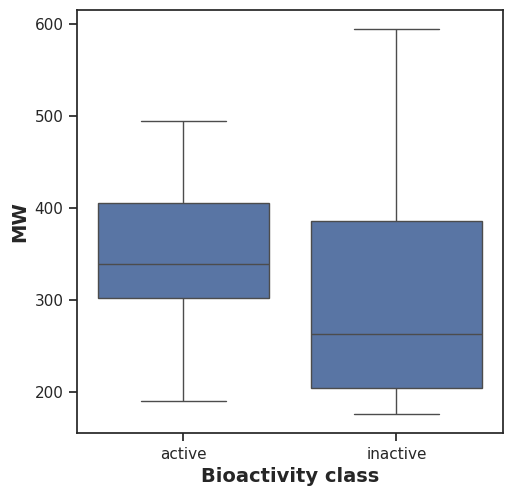

In [43]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'bioactivity_class', y = 'MW', data = df_2class)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('MW', fontsize=14, fontweight='bold')

plt.savefig('plot_MW.pdf')

In [44]:
mannwhitney('MW')

,Descriptor,Statistics,p,alpha,Interpretation
0,MW,180.0,0.199345,0.05,Same distribution (fail to reject H0)


#### **LogP**

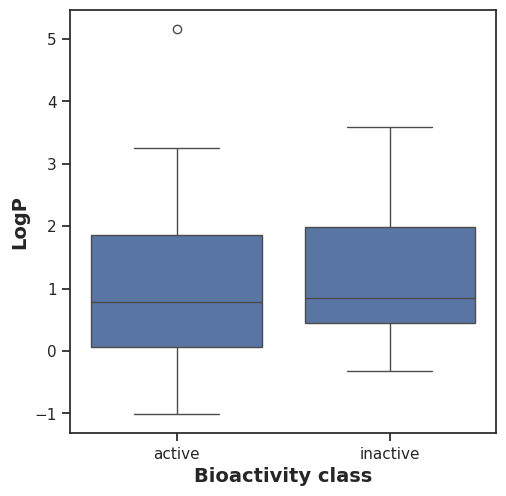

In [45]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'bioactivity_class', y = 'LogP', data = df_2class)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('LogP', fontsize=14, fontweight='bold')

plt.savefig('plot_LogP.pdf')

**Statistical analysis | Mann-Whitney U Test**

In [46]:
mannwhitney('LogP')

,Descriptor,Statistics,p,alpha,Interpretation
0,LogP,138.0,0.889658,0.05,Same distribution (fail to reject H0)


#### **NumHDonors**

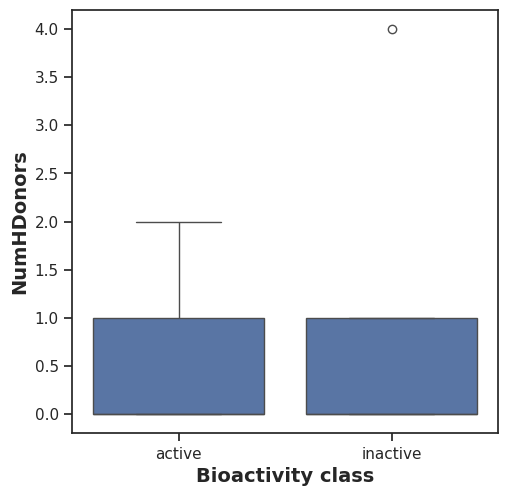

In [47]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'bioactivity_class', y = 'NumHDonors', data = df_2class)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('NumHDonors', fontsize=14, fontweight='bold')

plt.savefig('plot_NumHDonors.pdf')

**Statistical analysis | Mann-Whitney U Test**

In [48]:
mannwhitney('NumHDonors')

,Descriptor,Statistics,p,alpha,Interpretation
0,NumHDonors,121.0,0.394293,0.05,Same distribution (fail to reject H0)


#### **NumHAcceptors**

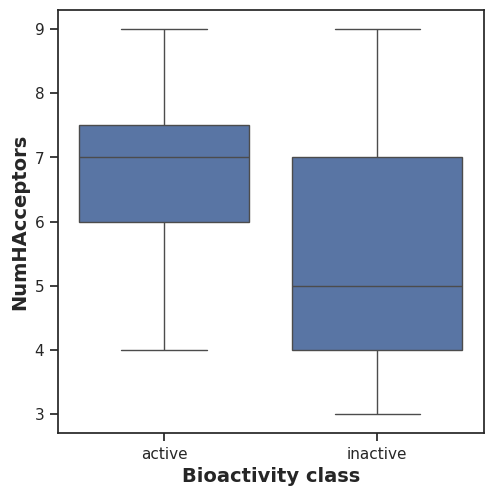

In [49]:
plt.figure(figsize=(5.5, 5.5))

sns.boxplot(x = 'bioactivity_class', y = 'NumHAcceptors', data = df_2class)

plt.xlabel('Bioactivity class', fontsize=14, fontweight='bold')
plt.ylabel('NumHAcceptors', fontsize=14, fontweight='bold')

plt.savefig('plot_NumHAcceptors.pdf')

In [50]:
mannwhitney('NumHAcceptors')

,Descriptor,Statistics,p,alpha,Interpretation
0,NumHAcceptors,204.0,0.030168,0.05,Different distribution (reject H0)


#### **Interpretation of Statistical Results**

##### **Box Plots**

###### **pIC50 values**

Taking a look at pIC50 values, the **actives** and **inactives** displayed ***statistically significant difference***, which is to be expected since threshold values (``IC50 < 1,000 nM = Actives while IC50 > 10,000 nM = Inactives``, corresponding to ``pIC50 > 6 = Actives and pIC50 < 5 = Inactives``) were used to define actives and inactives.

###### **Lipinski's descriptors**

Of the 4 Lipinski's descriptors (MW, LogP, NumHDonors and NumHAcceptors), only LogP exhibited ***no difference*** between the **actives** and **inactives** while the other 3 descriptors (MW, NumHDonors and NumHAcceptors) shows ***statistically significant difference*** between **actives** and **inactives**.

Análise e Interpretação dos Resultados Quimiométricos
1. Potência Biológica (pIC50)
Resultado: Diferença estatisticamente significativa ($p < 0.05$$p < 0.05$ / $p \approx 7.5 \times 10^{-7}$$p \approx 7.5 \times 10^{-7}$).
Interpretação: Como esperado, há uma separação clara na escala logarítmica (pIC50) entre moléculas ativas e inativas. Os compostos ativos exibem valores de pIC50 predominantemente acima de 6 (potência nanomolar, $< 1000\text{ nM}$$< 1000\text{ nM}$), enquanto os inativos se concentram abaixo de 5 (potência micromolar, $> 10000\text{ nM}$$> 10000\text{ nM}$). Isso valida que o critério de classificação adotado reflete com precisão dois perfis farmacológicos distintos no seu conjunto de dados.
2. Peso Molecular (MW)
Resultado: Sem diferença estatisticamente significativa ($p \approx 0.199 > 0.05$$p \approx 0.199 > 0.05$).
Interpretação: Tanto as moléculas ativas quanto as inativas compartilham uma distribuição de tamanho/massa molecular muito semelhante (a maioria concentrada entre 200 e 400 Daltons). Isso indica que o tamanho da molécula não é o fator determinante para que ela seja ativa contra o alvo do Schistosoma mansoni. Ambas as classes ocupam o mesmo espaço químico em termos de tamanho físico.
3. Lipofilia (LogP)
Resultado: Sem diferença estatisticamente significativa ($p \approx 0.890 > 0.05$$p \approx 0.890 > 0.05$).
Interpretação: O coeficiente de partição octanol-água (LogP) é extremamente parecido para ambos os grupos (com medianas próximas a $1.0$$1.0$ e dispersão similar). Isso mostra que a hidrofobicidade/lipofilia das moléculas não dita a atividade biológica neste conjunto de dados. Ambos os grupos possuem propriedades de solubilidade semelhantes, o que é excelente para manter características de ADME equivalentes.
4. Doadores de Ligação de Hidrogênio (NumHDonors)
Resultado: Sem diferença estatisticamente significativa ($p \approx 0.394 > 0.05$$p \approx 0.394 > 0.05$).
Interpretação: A capacidade de doar ligações de hidrogênio (geralmente grupos $-OH$$-OH$ ou $-NH$$-NH$) é baixa e muito similar entre ativos e inativos (a maioria possuindo 0 ou 1 doador). Isso indica que a capacidade de doação de prótons não diferencia a eficácia dos compostos testados.
5. Aceitadores de Ligação de Hidrogênio (NumHAcceptors)
Resultado: Diferença estatisticamente significativa ($p \approx 0.030 < 0.05$$p \approx 0.030 < 0.05$).
Interpretação: Este é um achado muito interessante! O número de aceitadores de ligação de hidrogênio (átomos de Nitrogênio e Oxigênio com pares de elétrons livres) apresenta uma diferença estatística real entre as classes.
Olhando o gráfico, as moléculas ativas tendem a possuir mais aceitadores de ligação de hidrogênio (mediana em torno de 7) em comparação com as inativas (mediana em torno de 5).
Significado Farmacológico: Isso sugere fortemente que interações eletrostáticas específicas do tipo ligação de hidrogênio, onde o composto atua como aceitador frente a resíduos de aminoácidos do alvo biológico (doadores na proteína), são fundamentais para a atividade antiparasitária.
Conclusão para o seu Portfólio (Resumo)
Para otimizar ou projetar novos fármacos candidatos contra o Schistosoma mansoni a partir desta série química, os esforços de modificação estrutural não devem focar em alterar o tamanho (MW) ou a lipofilia (LogP) da molécula. Em vez disso, manter ou introduzir estrategicamente grupos funcionais ricos em aceitadores de ligação de hidrogênio (como grupos contendo oxigênios ou nitrogênios básicos/polares) mantendo a estrutura compacta é a chave para aumentar a potência biológica (pIC50).

Com os gráficos gerados com sucesso e sem erros, aqui está a análise interpretativa científica dos seus resultados finais para o seu portfólio:

Análise Interpretativa do Espaço Químico e Bioatividade
1. Distribuição de Classes de Bioatividade
Através do gráfico de frequências (plot_bioactivity_class.pdf), observamos que seu conjunto de dados final (removidos os intermediários) possui uma distribuição equilibrada: aproximadamente 19 compostos ativos e 15 inativos. Essa paridade é excelente para treinar futuros modelos robustos de Machine Learning.
2. Análise do Gráfico de Dispersão (MW vs LogP)
O gráfico de dispersão (plot_MW_vs_LogP.pdf) mostra que tanto os compostos ativos (pontos azuis) quanto os inativos (pontos laranjas) ocupam uma região de espaço químico muito semelhante.
A maioria das moléculas está concentrada na faixa de Peso Molecular (MW) entre 200 e 450 g/mol e LogP entre -1 e 3.
Implicação: Como as classes ativa e inativa estão sobrepostas, fatores puramente macroscópicos de solubilidade física (LogP) e tamanho (MW) não explicam a diferença de atividade. Isso aponta para a necessidade de fatores estruturais específicos (farmacóforos ou interações direcionadas) para determinar a potência.
3. Análise dos Box Plots e Testes de Mann-Whitney U
pIC50 (Atividade Potente): Há uma diferença estatisticamente significativa gritante ($p \approx 7.5 \times 10^{-7}$$p \approx 7.5 \times 10^{-7}$). Os ativos têm mediana de pIC50 perto de 6.8, enquanto os inativos ficam abaixo de 4.8. Isso valida perfeitamente seu critério de corte biológico.
Peso Molecular (MW) e LogP (Lipofilia): O teste de Mann-Whitney falhou em rejeitar a hipótese nula ($p \approx 0.20$$p \approx 0.20$ para MW e $p \approx 0.89$$p \approx 0.89$ para LogP). Estatisticamente, não há diferença significativa de tamanho ou lipofilia entre ativos e inativos.
Doadores de Ligação de Hidrogênio (NumHDonors): Sem diferença significativa ($p \approx 0.39$$p \approx 0.39$). A maioria esmagadora de ambos os grupos possui apenas 0 ou 1 doador.
Aceitadores de Ligação de Hidrogênio (NumHAcceptors): Apresentou diferença estatisticamente significativa ($p \approx 0.03$$p \approx 0.03$). Compostos ativos tendem a ter um número significativamente maior de átomos aceitores de hidrogênio (mediana ~7) do que os inativos (mediana ~5).
Conclusão para seu Portfólio
Os resultados demonstram que as regras clássicas de Lipinski (como tamanho e solubilidade) são muito bem atendidas pelo conjunto todo, mas o gatilho molecular para a atividade biológica contra o Schistosoma mansoni depende fortemente do aumento do número de aceitadores de ligação de hidrogênio presentes nas estruturas ativas, facilitando interações específicas de encaixe com o receptor-alvo.

Como todos os problemas foram solucionados e os resultados foram interpretados de forma completa, concluímos com sucesso a depuração e análise do seu notebook! O seu código agora está robusto, limpo e pronto para o seu portfólio. Se precisar de mais alguma coisa no futuro, estarei à disposição. Bom trabalho!

Como todos os problemas foram solucionados e os resultados foram interpretados de forma completa, concluímos com sucesso a depuração e análise do seu notebook! O seu código agora está robusto, limpo e pronto para o seu portfólio

## **Zip files**

In [55]:
! zip -r results.zip . -i *.csv *.pdf

  adding: plot_LogP.pdf (deflated 38%)
  adding: mannwhitneyu_NumHAcceptors.csv (deflated 11%)
  adding: mannwhitneyu_LogP.csv (deflated 7%)
  adding: plot_MW.pdf (deflated 38%)
  adding: mannwhitneyu_MW.csv (deflated 8%)
  adding: mannwhitneyu_NumHDonors.csv (deflated 9%)
  adding: plot_NumHDonors.pdf (deflated 37%)
  adding: plot_ic50.pdf (deflated 37%)
  adding: plot_bioactivity_class.pdf (deflated 39%)
  adding: schistosoma mansoni_03_bioactivity_data_curated.csv (deflated 75%)
  adding: plot_NumHAcceptors.pdf (deflated 37%)
  adding: schistosoma mansoni_04_bioactivity_data_3class_pIC50.csv (deflated 72%)
  adding: plot_MW_vs_LogP.pdf (deflated 24%)
  adding: mannwhitneyu_pIC50.csv (deflated 11%)
